In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import cohen_kappa_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
PATH = "Data/combined_boardgames.csv"
data = pd.read_csv(PATH)

# split into binary and non-binary columns for AI
BIN = ["AI_IsCoherent", "AI_ClearObjective", "AI_ClearWin", "AI_MultipInteract"]
AI = BIN + ["AI_Confidence"]
print(data.shape)
data.head()

(21925, 49)


,BGGId,Name,YearPublished,GameWeight,AvgRating,BayesAvgRating,MinPlayers,MaxPlayers,ComAgeRec,NumOwned,...,ANN1_IsCoherent,ANN1_ClearObjective,ANN1_ClearWin,ANN1_MultipInteract,ANN1_Confidence,ANN2_IsCoherent,ANN2_ClearObjective,ANN2_ClearWin,ANN2_MultipInteract,ANN2_Confidence
0,1,Die Macher,1986,4.3206,7.61428,7.10363,3,5,14.366667,7498,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Dragonmaster,1981,1.9630,6.64537,5.78447,3,4,NaN,1285,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Samurai,1998,2.4859,7.45601,7.23994,2,4,9.307692,15578,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Tal der Könige,1992,2.6667,6.60006,5.67954,2,4,13.000000,638,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Acquire,1964,2.5031,7.33861,7.14189,2,6,11.410256,23735,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Preparing the data for analysis

1. Removing games with an empty description

429 games have no description. For these, the annotation script did not ask the model; it assigned fixed placeholder labels:

| IsCoherent | ClearObjective | ClearWin | MultipInteract | Confidence |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 1 |

These labels mean "there was no text, not "the description is bad". Keeping them would create an artificial 0-0-0-0-1 group of 429 games and bias every comparison, so these games are removed. 21,495 games remain.


2. Turning "fake zeros" into missing values (NaN)

Some zeros mean unknown, not an actual value of zero:
- `GameWeight` = 0: nobody voted on the game's complexity (real weights range from 1 to 5).
- `MfgPlaytime` = 0: the publisher did not state a playing time.
- `YearPublished` ≤ 0: 0 means the year is unknown; negative values are ancient games dated BC (e.g. Go), which would heavily distort any analysis involving year.

Setting them to NaN makes pandas ignore them in means, correlations and models instead of treating them as real zeros.

3. New variables

- `desc_words`: number of words in the description. Used to check whether the AI labels simply reflect description length (`log_words` is its log₁₀).
- `log_ratings`, `log_playtime`: log₁₀ of `NumUserRatings` and `MfgPlaytime`. Length, number of ratings and playtime are heavily right-skewed (e.g. median description 158 words, maximum 2,588), so the log keeps a few extreme games from dominating the regression and the clustering. It does not change Spearman correlations, which only use ranks.
- `AI_Score`: one overall description-quality score from 0 (worst) to 6 (best):

  `AI_Score = IsCoherent + ClearObjective + ClearWin + MultipInteract + (Confidence − 1)`

  Confidence goes from 1 to 3, so subtracting 1 turns it into 0–2 and puts it on the same footing as the binary labels.
  Example: labels 1, 1, 0, 1 with Confidence 2 → 1 + 1 + 0 + 1 + (2 − 1) = 4.
- `combo`: the five labels joined into one readable code, in the order Coherent-Objective-Win-Interaction-Confidence.
  Example: 1-1-0-1-2 = coherent, clear objective, no clear win condition, interaction described, Confidence 2.
  With 2 × 2 × 2 × 2 × 3 = 48 possible codes, this makes it easy to count how often each pattern of labels occurs.

In [3]:
desc = data["description"].fillna("")
empty = desc.str.strip().eq("")
print(f"Empty descriptions removed: {empty.sum()}")
d = data[~empty & data[AI].notna().all(axis=1)].copy()
d[AI] = d[AI].astype(int)
d["desc_words"] = d["description"].str.split().str.len()
d["log_words"] = np.log10(d["desc_words"])
d["log_ratings"] = np.log10(d["NumUserRatings"])
for c in ["GameWeight", "MfgPlaytime"]:
    d[c] = d[c].replace(0, np.nan)
d.loc[d["YearPublished"] <= 0, "YearPublished"] = np.nan
d["log_playtime"] = np.log10(d["MfgPlaytime"])

d["AI_Score"] = d[BIN].sum(axis=1) + d["AI_Confidence"] - 1
d["combo"] = d[AI].astype(str).agg("-".join, axis=1)
print(f"Analysis set: {len(d):,} games")

Empty descriptions removed: 429
Analysis set: 21,495 games


### Distributions and combinations

In [4]:
marg = pd.DataFrame({
    "share = 1 (yes) (%)": [100 * d[c].mean() for c in BIN] + [np.nan],
})
marg.index = BIN + ["AI_Confidence"]
conf = d["AI_Confidence"].value_counts(normalize=True).sort_index() * 100
print("Binary labels, share of games with label 1 (yes):")
display(marg.iloc[:4].round(1))
print("AI_Confidence distribution (%):", conf.round(1).to_dict())
print("AI_Score distribution (%):", (d["AI_Score"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

Binary labels, share of games with label 1 (yes):


,share = 1 (yes) (%)
AI_IsCoherent,99.8
AI_ClearObjective,83.6
AI_ClearWin,46.9
AI_MultipInteract,74.1


AI_Confidence distribution (%): {1: 5.7, 2: 59.3, 3: 35.0}
AI_Score distribution (%): {0: 0.0, 1: 4.9, 2: 7.6, 3: 12.8, 4: 31.5, 5: 9.9, 6: 33.3}


Let's look a bit more into the combinations that produced the AI_score shares:

In [5]:
combos = (d.groupby("combo")
            .agg(games=("BGGId", "size"), median_words=("desc_words", "median"),
                 mean_rating=("AvgRating", "mean"))
            .sort_values("games", ascending=False))
combos["share_%"] = 100 * combos["games"] / len(d)
print(f"{len(combos)} distinct combinations out of 48 possible")
display(combos.head(10)[["games", "share_%", "median_words", "mean_rating"]])

29 distinct combinations out of 48 possible


,games,share_%,median_words,mean_rating
combo,,,,
1-1-1-1-3,7164,33.328681,202.0,6.317218
1-1-0-1-2,5974,27.792510,161.0,6.536567
1-1-0-0-2,1833,8.527565,107.0,6.306077
1-1-1-1-2,1764,8.206560,143.0,6.216261
1-0-0-0-2,1479,6.880670,143.0,6.734717
1-0-0-0-1,1047,4.870900,69.0,6.416641
1-0-0-1-2,877,4.080019,182.0,6.844649
1-1-1-0-2,770,3.582228,110.5,5.995859
1-1-1-0-3,351,1.632938,137.0,6.211701


The AI assigns Confidence 1 to ~6% of games, 2 to ~59% and 3 to ~35%. The most common AI_Score values are 6 (33%) and 4 (32%).

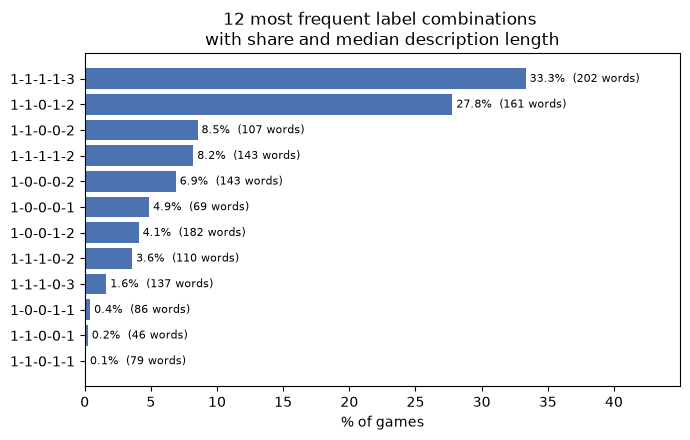

In [6]:
top = combos.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top["share_%"], color="#4C72B0")
for y, (s, w) in enumerate(zip(top["share_%"], top["median_words"])):
    ax.text(s + 0.3, y, f"{s:.1f}%  ({w:.0f} words)", va="center", fontsize=8)
ax.set_xlabel("% of games")
ax.set_title("12 most frequent label combinations \nwith share and median description length")
ax.set_xlim(0, top["share_%"].max() * 1.35)
plt.tight_layout()
plt.show();

The top 10 combinations cover 99.3% of games; each of the remaining 19 accounts for 0.2% or less.

### Description length

In [7]:
print(d["desc_words"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0))

rows = []
for c in AI + ["AI_Score"]:
    lo, hi = d[c].min(), d[c].max()
    rows.append({"feature": c, "lowest label": lo, "median words (lowest)": d.loc[d[c] == lo, "desc_words"].median(),
                 "highest label": hi, "median words (highest)": d.loc[d[c] == hi, "desc_words"].median(),
                 "Spearman rho with length": stats.spearmanr(d[c], d["desc_words"])[0]})
display(pd.DataFrame(rows).set_index("feature").round(2))

count    21495.0
mean       190.0
std        133.0
min          6.0
10%         67.0
25%        102.0
50%        158.0
75%        241.0
90%        346.0
max       2588.0
Name: desc_words, dtype: float64


,lowest label,median words (lowest),highest label,median words (highest),Spearman rho with length
feature,,,,,
AI_IsCoherent,0,145.0,1,158.0,0.01
AI_ClearObjective,0,121.0,1,164.0,0.16
AI_ClearWin,0,140.0,1,179.0,0.19
AI_MultipInteract,0,109.0,1,176.0,0.31
AI_Confidence,1,70.0,3,199.0,0.32
AI_Score,0,85.0,6,202.0,0.31


For each feature, the table compares the median description length (in words) of games with the lowest vs. the highest label, and gives the Spearman correlation with length across all games.
- Every label increases with length: better-rated descriptions are longer (e.g. Confidence 1 → 70 words, Confidence 3 → 199 words).
- The relationship is only weak to moderate (ρ ≤ 0.32): length explains part of the labels, but not all of them.
- `AI_IsCoherent` is unrelated to length (ρ = 0.01); the `AI_Score = 0` median rests on only 9 games.

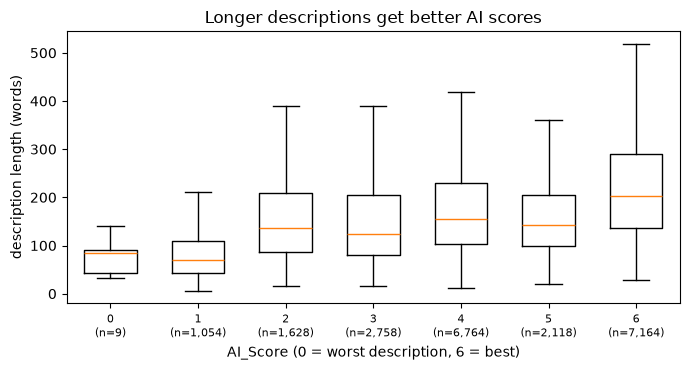

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
groups = [d.loc[d["AI_Score"] == s, "desc_words"] for s in range(7)]
ax.boxplot(groups, positions=range(7), showfliers=False, widths=0.6)
ax.set_xticks(range(7))
ax.set_xticklabels([f"{s}\n(n={len(g):,})" for s, g in enumerate(groups)], fontsize=8)
ax.set_xlabel("AI_Score (0 = worst description, 6 = best)")
ax.set_ylabel("description length (words)")
ax.set_title("Longer descriptions get better AI scores")
plt.tight_layout()
plt.show();

In [9]:
d["length_decile"] = pd.qcut(d["desc_words"], 10, labels=False) + 1
within = d.groupby("length_decile").agg(
    words=("desc_words", "median"),
    mean_AI_Score=("AI_Score", "mean"),
    sd_AI_Score=("AI_Score", "std"),
    pct_perfect=("AI_Score", lambda s: 100 * (s == 6).mean()),
    pct_ClearWin=("AI_ClearWin", lambda s: 100 * s.mean()),
)
display(within.round(2))
r2_len = np.corrcoef(d["log_words"], d["AI_Score"])[0, 1] ** 2
print(f"Share of AI_Score variance explained by (log) length alone: R^2 = {r2_len:.2f}")

,words,mean_AI_Score,sd_AI_Score,pct_perfect,pct_ClearWin
length_decile,,,,,
1,52.0,3.11,1.55,7.94,24.37
2,79.0,3.84,1.49,18.79,36.68
3,102.0,4.09,1.44,23.65,41.22
4,123.0,4.32,1.38,28.91,46.07
5,146.0,4.43,1.38,32.67,48.33
6,171.0,4.49,1.35,34.80,48.42
7,202.0,4.67,1.32,41.14,53.51
8,241.0,4.70,1.35,44.84,53.80
9,300.0,4.83,1.32,49.05,57.65


Share of AI_Score variance explained by (log) length alone: R^2 = 0.12


Games are split into 10 equal groups by description length (decile 1 = shortest 10%, 10 = longest 10%). For each group: median length (`words`), mean and standard deviation of `AI_Score`, % of "perfect" descriptions (`AI_Score = 6`) and % with a clear win condition.
- Labels improve steadily with length: mean AI_Score rises from 3.1 to 4.9, perfect descriptions from 8% to 52%, and `ClearWin` from 24% to 60%.
- Most of the gain happens in the shortest deciles.
- Yet the spread within each group stays large (SD ≈ 1.3–1.5 points), and length alone explains only 12% of the AI_Score variance (R² = 0.12): descriptions of the same length can receive very different labels, so the AI features capture content, not just text length.

### Correlations

Spearman correlation is used throughout because the AI labels are binary or ordinal (Confidence 1–3) and several game features are heavily skewed: Spearman only uses the ranks of the values, so it makes no assumption of a linear relationship and is not driven by extreme games.

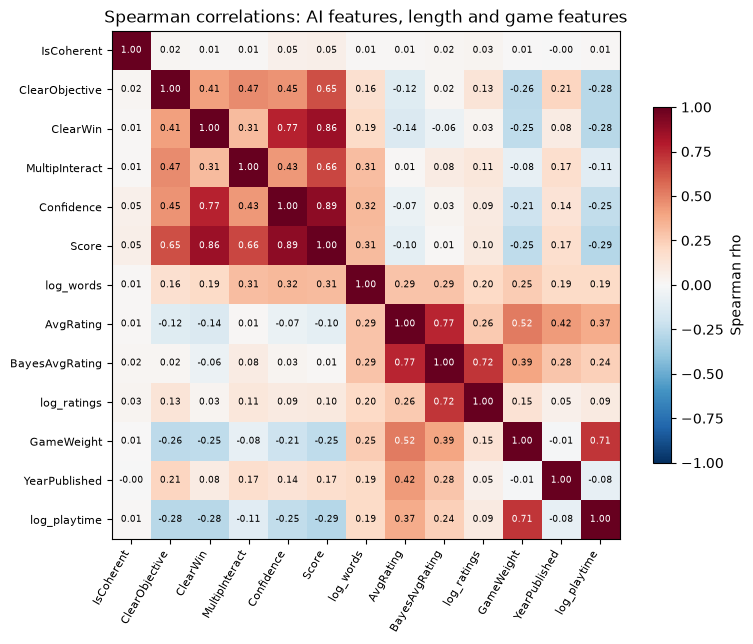

In [10]:
cols = AI + ["AI_Score", "log_words", "AvgRating", "BayesAvgRating", "log_ratings",
             "GameWeight", "YearPublished", "log_playtime"]
corr = d[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels([c.replace("AI_", "") for c in cols], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels([c.replace("AI_", "") for c in cols], fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
fig.colorbar(im, shrink=0.7, label="Spearman rho")
ax.set_title("Spearman correlations: AI features, length and game features")
plt.tight_layout(); plt.show()

In [11]:
rows = []
for c in AI + ["AI_Score", "log_words"]:
    m = d[[c, "AvgRating"]].dropna()
    r, p = stats.spearmanr(m[c], m["AvgRating"])
    rows.append({"feature": c, "Spearman rho": round(r, 2), "p-value": p,
                 "significant (p < 0.05)": p < 0.05})

display(pd.DataFrame(rows).set_index("feature"))

,Spearman rho,p-value,significant (p < 0.05)
feature,,,
AI_IsCoherent,0.01,1.285042e-01,False
AI_ClearObjective,-0.12,7.454402e-68,True
AI_ClearWin,-0.14,1.549266e-97,True
AI_MultipInteract,0.01,1.156369e-01,False
AI_Confidence,-0.07,5.519460e-23,True
AI_Score,-0.10,4.763115e-50,True
log_words,0.29,0.000000e+00,True


Spearman ρ between each feature and the average user rating (n ≈ 21,500 games).
- The AI labels are only weakly related to rating, and mostly negatively: descriptions that state the objective (ρ = −0.12) or the win condition (ρ = −0.14) belong to slightly lower-rated games; `IsCoherent` and `MultipInteract` show no relation.
- Description length is the strongest signal (ρ = +0.29): games with longer descriptions tend to be rated higher (p = 0 means the p-value is smaller than the computer can represent).
- With ~21,500 games even tiny effects are "significant", so the size of ρ matters more than the p-value: all AI correlations are weak (|ρ| ≤ 0.14).

### How AI features explain game quality beyond the usual features

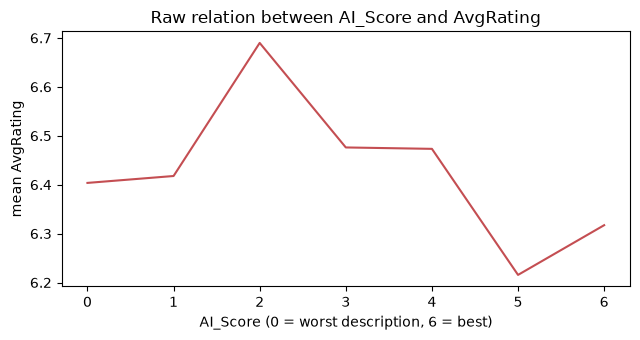

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
g = d.groupby("AI_Score")["AvgRating"].mean()
ax.plot(g.index, g.values, "-", color="#C44E52")
ax.set_xlabel("AI_Score (0 = worst description, 6 = best)")
ax.set_ylabel("mean AvgRating")
ax.set_title("Raw relation between AI_Score and AvgRating")
plt.tight_layout()
plt.show();

The raw relation is not monotonic: the mean rating peaks at AI_Score 2 (6.69) and is lowest at 5 (6.22), consistent with the weak negative Spearman correlation (ρ = −0.10). The point at AI_Score 0 rests on only 9 games and should be ignored.

**Model set-up.** Three nested linear models predict `AvgRating`:
- **M1**: standard game features (weight, year, log number of ratings, min/max players, log playtime, Kickstarter, reimplementation, the 8 category flags);
- **M2**: M1 + description length (`log_words`);
- **M3**: M2 + the five AI labels.

Choices made before looking at the results:
- **Outcome `AvgRating`, not `BayesAvgRating`**: the Bayesian average pulls games with few ratings toward the overall mean, so it mixes popularity into the score; popularity is already a control (`log_ratings`).
- **Complete cases only**: games with a missing weight, playtime or year are dropped.
- **`MaxPlayers` > 20 removed**: these are placeholder values (median 99, maximum 999 = "unlimited"), not real player counts.
- **Games published before 1950 removed**: dates go back to 400 AD, and these few games would have extreme leverage on a linear year effect.

The cell after the results checks how much these choices matter.

In [13]:
CATS = [c for c in d.columns if c.startswith("Cat:")]
CONTROLS = ["GameWeight", "YearPublished", "log_ratings", "MinPlayers", "MaxPlayers",
            "log_playtime", "Kickstarted", "IsReimplementation"] + CATS

m = d.dropna(subset=CONTROLS + ["AvgRating", "log_words"]).copy()
m = m[(m["YearPublished"] >= 1950) & (m["MaxPlayers"] <= 20)]          # see markdown above: placeholder player counts / extreme years
print(f"Regression sample: {len(m):,} games, SD of AvgRating = {m['AvgRating'].std():.2f}")

def ols(y, X):
    X = np.column_stack([np.ones(len(X)), X])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    n, k = X.shape
    cov = XtX_inv @ (X.T * e**2) @ X @ XtX_inv * n / (n - k)       # HC1 robust
    se = np.sqrt(np.diag(cov))
    r2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
    adj = 1 - (1 - r2) * (n - 1) / (n - k)
    return beta[1:], se[1:], r2, adj

y = m["AvgRating"].to_numpy()
specs = {"M1 controls": CONTROLS, "M2 + length": CONTROLS + ["log_words"],
         "M3 + AI features": CONTROLS + ["log_words"] + AI}
fits = {}
for name, cols_ in specs.items():
    fits[name] = (cols_, *ols(y, m[cols_].to_numpy(float)))
    print(f"{name:18s} R2 = {fits[name][3]:.4f}   adj R2 = {fits[name][4]:.4f}")

cols_, b, se, *_ = fits["M3 + AI features"]
coef = pd.DataFrame({"coef": b, "robust SE": se}, index=cols_)
coef["t"] = coef["coef"] / coef["robust SE"]
coef["p"] = 2 * stats.norm.sf(coef["t"].abs())
print("\nM3: coefficients of description variables (effect on AvgRating, all controls held fixed)")
display(coef.loc[["log_words"] + AI].round(4))

Regression sample: 19,741 games, SD of AvgRating = 0.90
M1 controls        R2 = 0.4594   adj R2 = 0.4589
M2 + length        R2 = 0.4618   adj R2 = 0.4613
M3 + AI features   R2 = 0.4658   adj R2 = 0.4652

M3: coefficients of description variables (effect on AvgRating, all controls held fixed)


,coef,robust SE,t,p
log_words,0.2326,0.0216,10.7485,0.0000
AI_IsCoherent,-0.0248,0.1032,-0.2405,0.8099
AI_ClearObjective,-0.1303,0.0182,-7.1464,0.0000
AI_ClearWin,-0.0926,0.0153,-6.0671,0.0000
AI_MultipInteract,-0.0088,0.0132,-0.6666,0.5050
AI_Confidence,0.0325,0.0150,2.1737,0.0297


**Regression results** (19,741 complete games). M1 uses only the standard game features, M2 adds description length, and M3 adds the five AI labels. The coefficients are M3's, i.e. each variable's effect on AvgRating with all other features held fixed.
- Standard features already explain ~46% of the variation in rating (R² = 0.459); length adds +0.002 and the AI labels a further +0.004: a small but real improvement.
- Length has a clear positive effect: a description 10× longer goes with a +0.23 higher rating.
- Stating the objective (−0.13) or the win condition (−0.09) goes with a slightly lower rating even after controlling for weight, year, popularity and category; Confidence has a small positive effect (+0.03 per level, p = 0.03).
- `IsCoherent` and `MultipInteract` have no effect (p > 0.5). All effects are small compared with the spread of ratings (SD ≈ 0.9), so the AI labels describe how a game is presented rather than strongly predicting how good it is: they judge the text written about the game, not the game itself.

In [14]:
# Robustness: M3 coefficients of the description variables under the alternative choices
# (* = significant at 5%, robust SE)
def m3_coefs(sample, outcome):
    cols_ = CONTROLS + ["log_words"] + AI
    b, se, *_ = ols(sample[outcome].to_numpy(), sample[cols_].to_numpy(float))
    t = b / se
    return pd.Series([f"{bi:+.3f}{'*' if abs(ti) > 1.96 else ''}" for bi, ti in zip(b, t)], index=cols_).loc[["log_words"] + AI]

full = d.dropna(subset=CONTROLS + ["AvgRating", "log_words"])
robust = pd.DataFrame({
    f"main: AvgRating, filtered (n={len(m):,})": m3_coefs(m, "AvgRating"),
    f"AvgRating, no filters (n={len(full):,})": m3_coefs(full, "AvgRating"),
    f"BayesAvgRating, filtered (n={len(m):,})": m3_coefs(m, "BayesAvgRating"),
})
display(robust)

,"main: AvgRating, filtered (n=19,741)","AvgRating, no filters (n=20,157)","BayesAvgRating, filtered (n=19,741)"
log_words,+0.233*,+0.390*,+0.000
AI_IsCoherent,-0.025,-0.076,-0.023
AI_ClearObjective,-0.130*,-0.077*,-0.005
AI_ClearWin,-0.093*,-0.121*,-0.010*
AI_MultipInteract,-0.009,+0.013,-0.006
AI_Confidence,+0.033*,+0.037*,+0.003


**Robustness.** Without the two filters, the AI effects keep the same sign and significance (objective −0.08, win condition −0.12, Confidence +0.04), only their size shifts.

### Reliability: AI vs human annotators

Two team members annotated the same 90 games. Cohen's kappa measures agreement beyond chance (quadratic-weighted for Confidence, which is ordinal). If the AI agrees with each human about as well as the humans agree with each other, it labels at human level.

In [17]:
h = data.dropna(subset=["ANN1_IsCoherent", "ANN2_IsCoherent"] + AI)
rows = []
for n_ in [c.replace("AI_", "") for c in AI]:
    a, h1, h2 = h[f"AI_{n_}"].astype(int), h[f"ANN1_{n_}"].astype(int), h[f"ANN2_{n_}"].astype(int)
    w = "quadratic" if n_ == "Confidence" else None
    rows.append({"metric": n_,
                 "kappa AI-ANN1": cohen_kappa_score(a, h1, weights=w),
                 "kappa AI-ANN2": cohen_kappa_score(a, h2, weights=w),
                 "kappa ANN1-ANN2": cohen_kappa_score(h1, h2, weights=w),
                 "mean AI": a.mean(), "mean humans": (h1.mean() + h2.mean()) / 2})
print(f"{len(h)} games annotated by both humans")
display(pd.DataFrame(rows).set_index("metric").round(2))

90 games annotated by both humans


,kappa AI-ANN1,kappa AI-ANN2,kappa ANN1-ANN2,mean AI,mean humans
metric,,,,,
IsCoherent,-0.02,-0.02,1.00,0.99,0.97
ClearObjective,0.53,0.60,0.63,0.87,0.77
ClearWin,0.66,0.64,0.88,0.52,0.61
MultipInteract,0.42,0.52,0.73,0.77,0.75
Confidence,0.60,0.59,0.85,2.31,2.19


AI–human agreement is moderate (κ ≈ 0.42–0.66) and below the agreement between the two humans (κ ≈ 0.63–0.88), especially for interaction and Confidence. The AI is stricter than the humans on the win condition and more generous on the objective. `IsCoherent` shows no agreement beyond chance because almost every description is labelled coherent. This is the main limitation of labels produced by a small local model, and the estimate rests on only 90 games.